# Notebook 1: measuring gland space through depth

This notebook turns each 2D level of a 3D prostate biopsy into two numbers, measured in 1 mm windows along the core:

* **lumen fraction** (gland space): how much of the tissue is open gland lumen. Well-formed glands have open centres; higher-grade cancer crowds and fuses them.
* **nuclei fraction**: how much of the tissue is cell nuclei.

Notebook 2 then asks how quickly these numbers change with depth.

**Data.** 12 complete biopsy stacks from the public TRICARE prostate development cohort (Gao et al., *Nat Biomed Eng* 2026; Zenodo doi:10.5281/zenodo.20052262). Each stack has 33 virtual levels about 5 µm apart.

**Expected layout.** `prostate_development_cohort_part_001.zip` in the folder above this repository (or edit `ZIP_PATH`). The notebook extracts the 12 cores into `slices/` and writes results to `outputs/`. Runtime is about 15 to 25 minutes.

## Step 0: Setup and settings

Loads libraries, defines every adjustable setting in one place, extracts the 12 cores from the zip if needed, and lists every slice with its depth.

* **Cores:** 3 patients (P000, P001, P002); 6 labelled higher grade (`tumor_tissue` in the dataset spreadsheet) and 6 labelled low grade (`normal_tissue`). In this dataset `normal_tissue` means low-grade cancer, not healthy tissue. The label describes the annotated middle level of each core.
* **Voxel size:** 0.44 µm at acquisition, downsampled 2x to about 0.88 µm (Gao et al.). The code uses 0.9 µm; the 2% difference doesn't affect the conclusions.
* **Alignment:** every level of a core is a virtual section through one 3D image, so the same pixel rows in two levels are the same place in the biopsy at different depths.

In [1]:
# ============================================================
# STEP 0: SETUP
# ============================================================

# ---- Toolboxes ------------------------------------------------
import zipfile                       # reads files out of a .zip without unzipping all 7 GB
from pathlib import Path             # handles file and folder paths cleanly
import numpy as np                   # numpy: an image is just a grid of numbers, numpy does the maths on grids
import pandas as pd                  # pandas: tables, like a spreadsheet inside Python
from PIL import Image                # Pillow: opens the .tiff image files
from scipy import ndimage as ndi     # scipy.ndimage: label blobs, fill holes, grow shapes outwards
from skimage import color, filters, transform   # scikit-image: colour maths, automatic thresholds, resizing
import matplotlib.pyplot as plt      # matplotlib: draws pictures and plots

# ---- Where the files are ---------------------------------------
# Jupyter runs from the folder the notebook is saved in, so these are relative to the notebook.
HERE       = Path.cwd()                                           # this folder (tricare_prostate)
ZIP_PATH   = HERE.parent / "prostate_development_cohort_part_001.zip"   # the Zenodo download, one folder up
SLICE_DIR  = HERE / "slices"                                      # where the extracted slices live
OUT_DIR    = HERE / "outputs"                                     # where results get saved
OUT_DIR.mkdir(exist_ok=True)                                      # make outputs/ if it isn't there yet

# ---- Which cores, and what the dataset says about them -------
# Labels copied from prostate_development_cohort.csv on Zenodo (record 20052262).
# tumor_tissue  = higher grade prostate cancer
# normal_tissue = low grade prostate cancer  (NOT healthy tissue)
CORES = {
    # patient P000
    "PRD_P000_A":  "higher grade",
    "PRD_P000_B":  "low grade",
    "PRD_P000_C1": "low grade",
    "PRD_P000_C2": "higher grade",
    "PRD_P000_D1": "low grade",
    # patient P001
    "PRD_P001_B":  "higher grade",
    "PRD_P001_D1": "higher grade",
    "PRD_P001_E":  "low grade",
    "PRD_P001_F2": "higher grade",
    # patient P002
    "PRD_P002_A":  "higher grade",
    "PRD_P002_B":  "low grade",
    "PRD_P002_F":  "low grade",
}

# ---- Every adjustable setting, in one place ----------------------
PIXEL_UM        = 0.9    # voxel size in µm (Gao et al. give 0.88: 0.44 µm imaging, downsampled 2x)
SHRINK          = 2      # make images 2x smaller in each direction: 0.9 µm -> 1.8 µm per pixel
WINDOW_UM       = 1000   # measure in windows 1 mm long along the core
MIN_TISSUE_FRAC = 0.25   # skip a window if tissue fills less than 25% of it (ragged ends of the core)
MIN_SPECK_PX    = 100    # tissue blobs smaller than this many pixels are dust or debris, not tissue
EDGE_CLOSE_PX   = 15     # edge fix: seal gaps in the core's edge narrower than about 2 x 15 px (≈ 54 µm)
NUCLEI_GRAY_MAX = 0.55   # a tissue pixel darker than this (0 = black, 1 = white) counts as nucleus
MIN_LUMEN_PX    = 40     # white holes smaller than this (about 130 µm²) are too small to be a lumen
RING_PX         = 8      # width of the ring we inspect around each hole (8 px x 1.8 µm ≈ 14 µm, about one cell)
RING_NUCLEI_MIN = 0.20   # a hole counts as a lumen if at least 20% of its ring is nuclei (i.e. it is lined by cells)

UM_PER_PX  = PIXEL_UM * SHRINK                       # size of a pixel after shrinking
WINDOW_PX  = int(round(WINDOW_UM / UM_PER_PX))       # how many pixel rows make 1 mm
print(f"After shrinking, 1 pixel ≈ {UM_PER_PX} µm, so a 1 mm window = {WINDOW_PX} rows")

# ---- Pull the cores out of the zip (only if missing) ----
SLICE_DIR.mkdir(exist_ok=True)
for core in CORES:
    already = list(SLICE_DIR.glob(f"{core}_*.tiff"))
    if len(already) >= 33:
        print(f"{core}: {len(already)} slices already in slices/")
        continue
    with zipfile.ZipFile(ZIP_PATH) as z:                             # open the zip (reads only its index)
        wanted = [n for n in z.namelist() if n.startswith(core + "_")]
        for n in wanted:
            z.extract(n, SLICE_DIR)                                  # copy just this one file out
    print(f"{core}: pulled {len(wanted)} slices out of the zip")

# ---- Make a list of every slice: which core, what depth, which file ----
def depth_of(path):
    # File names look like PRD_P000_A_335.tiff. The last number is the depth position.
    return int(path.stem.split("_")[-1])

slices = []
for core in CORES:
    files = sorted(SLICE_DIR.glob(f"{core}_*.tiff"), key=depth_of)   # sort from top to bottom
    top = depth_of(files[0])
    for f in files:
        slices.append({"core": core,
                       "grade": CORES[core],
                       "depth_um": round((depth_of(f) - top) * PIXEL_UM, 1),   # depth below the first slice, in µm
                       "file": f})
slices = pd.DataFrame(slices)
print(slices.groupby("core")["depth_um"].agg(["count", "min", "max"]))

After shrinking, 1 pixel ≈ 1.8 µm, so a 1 mm window = 556 rows
PRD_P000_A: 33 slices already in slices/
PRD_P000_B: 33 slices already in slices/
PRD_P000_C1: 33 slices already in slices/
PRD_P000_C2: 33 slices already in slices/
PRD_P000_D1: 33 slices already in slices/
PRD_P001_B: 33 slices already in slices/
PRD_P001_D1: 33 slices already in slices/
PRD_P001_E: 33 slices already in slices/
PRD_P001_F2: 33 slices already in slices/
PRD_P002_A: 33 slices already in slices/
PRD_P002_B: 33 slices already in slices/
PRD_P002_F: 33 slices already in slices/
             count  min    max
core                          
PRD_P000_A      33  0.0  160.2
PRD_P000_B      33  0.0  160.2
PRD_P000_C1     33  0.0  160.2
PRD_P000_C2     33  0.0  160.2
PRD_P000_D1     33  0.0  160.2
PRD_P001_B      33  0.0  160.2
PRD_P001_D1     33  0.0  160.2
PRD_P001_E      33  0.0  160.2
PRD_P001_F2     33  0.0  160.2
PRD_P002_A      33  0.0  160.2
PRD_P002_B      33  0.0  160.2
PRD_P002_F      33  0.0  160.2


**Result.** At 1.8 µm per pixel after shrinking, a 1 mm window is 556 rows. All 12 cores have 33 levels spanning 0 to 160 µm of depth.

## Step 1: Load one slice and shrink it

Each level is an RGB image. Images are averaged 2 x 2, giving 1.8 µm pixels, which still resolve lumens (tens of µm) and nuclei (about 6 to 10 µm) and run four times faster.

The images are false-coloured from two fluorescent channels (a nuclear dye and eosin) to resemble H&E.

file: PRD_P000_A_335.tiff | depth: 80.1 µm
shrunk image size (rows, columns, colours): (7242, 513, 3)
core length ≈ 13.0 mm, width ≈ 0.92 mm


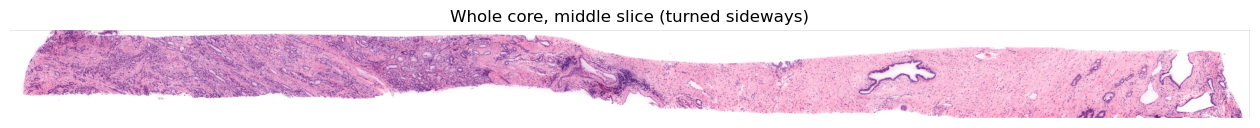

In [2]:
# ============================================================
# STEP 1: LOAD ONE SLICE AND SHRINK IT
# ============================================================

def load_slice(path):
    rgb = np.asarray(Image.open(path))                             # full size: rows x columns x 3 colours
    small = transform.downscale_local_mean(rgb, (SHRINK, SHRINK, 1))   # average each SHRINK x SHRINK block
    return small.astype(np.uint8)                                  # back to whole numbers 0 to 255

# Pick the middle slice of the higher grade core as the example.
example = slices[(slices.core == "PRD_P000_A")].iloc[16]
img = load_slice(example.file)

print("file:", example.file.name, "| depth:", example.depth_um, "µm")
print("shrunk image size (rows, columns, colours):", img.shape)
print(f"core length ≈ {img.shape[0] * UM_PER_PX / 1000:.1f} mm, width ≈ {img.shape[1] * UM_PER_PX / 1000:.2f} mm")

# Show the whole core, turned on its side so it fits the screen.
plt.figure(figsize=(16, 2))
plt.imshow(np.rot90(img))
plt.title("Whole core, middle slice (turned sideways)")
plt.axis("off")
plt.savefig(OUT_DIR / "step1_whole_core.png", dpi=120, bbox_inches="tight")
plt.show()

**Result.** The example level (`PRD_P000_A_335`, the annotated middle level) is 7242 x 513 pixels after shrinking: about 13 mm long and 0.92 mm wide, as expected for a needle core. Dark purple areas are dense with nuclei; pink is stroma; white holes are lumens or cracks.

## Step 2: Brightness and saturation

Two numbers per pixel replace the colour image:

* **saturation** separates coloured tissue from white (background and lumens), using Otsu's automatic threshold;
* **brightness** picks out nuclei, the darkest pixels.

A standard H&E stain-separation transform (`rgb2hed`) was tested first. On these false-coloured images it labelled most tissue as nuclei, so the simpler brightness and saturation measures are used instead.

Otsu cut on saturation for this slice: 0.159


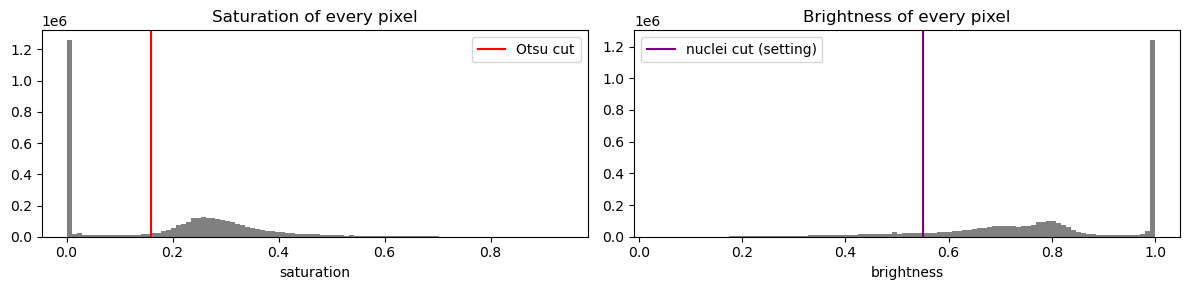

In [3]:
# ============================================================
# STEP 2: BRIGHTNESS AND SATURATION
# ============================================================

def colour_channels(img):
    gray = color.rgb2gray(img)              # brightness, 0 (black) to 1 (white)
    sat  = color.rgb2hsv(img)[..., 1]       # saturation, the S in Hue-Saturation-Value
    return gray, sat

gray, sat = colour_channels(img)
sat_cut = filters.threshold_otsu(sat)       # automatic cut between "white" and "coloured"
print(f"Otsu cut on saturation for this slice: {sat_cut:.3f}")

# Histograms: expect a spike at 0 saturation (white) and a hump for tissue.
fig, ax = plt.subplots(1, 2, figsize=(12, 3))
ax[0].hist(sat.ravel(), bins=100, color="grey")
ax[0].axvline(sat_cut, color="red", label="Otsu cut")
ax[0].set_title("Saturation of every pixel"); ax[0].set_xlabel("saturation"); ax[0].legend()
ax[1].hist(gray.ravel(), bins=100, color="grey")
ax[1].axvline(NUCLEI_GRAY_MAX, color="purple", label="nuclei cut (setting)")
ax[1].set_title("Brightness of every pixel"); ax[1].set_xlabel("brightness"); ax[1].legend()
plt.tight_layout()
plt.savefig(OUT_DIR / "step2_histograms.png", dpi=120)
plt.show()

**Result.** Saturation is bimodal: a spike at 0 (white) and a tissue hump between about 0.2 and 0.4, with the Otsu cut (0.159) in the valley. Nuclei form the dark tail of the brightness histogram, below 0.55.

## Step 3: Outline the tissue

1. **Tissue:** pixels more saturated than the Otsu cut, with small specks removed.
2. **Edge sealing:** a morphological closing (grow by `EDGE_CLOSE_PX`, then shrink back) seals narrow openings in the core's edge. Without it, a gland cut open by the edge of the biopsy drops in and out of the count between levels, which looks like change with depth when it isn't. A 15 px radius recovered such glands with few side effects; 40 px added little and started counting edge notches.
3. **Outline:** the sealed shape with enclosed holes filled. White inside the outline is a candidate lumen; white outside is background.

Glands cut wide open by the biopsy edge can't be recovered; that is a stated limitation.

tissue covers 60.8% of the image, the outline covers 63.8%
white space inside the outline (lumens AND cracks, before step 5 sorts them): 4.7%


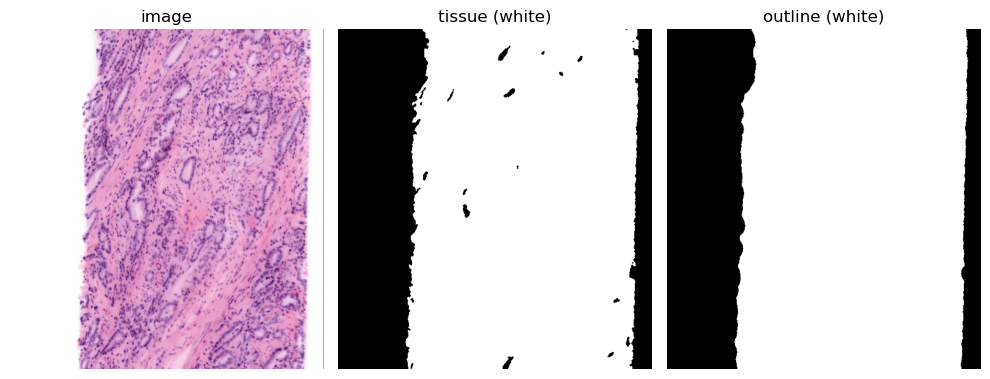

In [4]:
# ============================================================
# STEP 3: OUTLINE THE TISSUE
# ============================================================

def remove_small(mask, min_px):
    # Label every separate blob in a True/False mask, then keep only blobs of at least min_px pixels.
    labels, n = ndi.label(mask)                     # each blob gets its own number 1, 2, 3 ...
    sizes = np.bincount(labels.ravel())             # how many pixels each number has
    keep = sizes >= min_px
    keep[0] = False                                 # label 0 is "not part of any blob"
    return keep[labels]                             # back to a True/False mask

def close_by(mask, r):
    # "Closing": grow the shape outwards by r pixels, then shrink it back by r.
    # Gaps narrower than about 2r get sealed; everything else ends up where it started.
    # Done with distance maps (distance from every pixel to the nearest True pixel), which is fast even for big r.
    grown = ndi.distance_transform_edt(~mask) <= r        # every pixel within r of the tissue
    return ndi.distance_transform_edt(grown) > r          # then keep only pixels more than r inside the grown shape

def outline_tissue(sat):
    tissue = sat > filters.threshold_otsu(sat)              # coloured pixels = tissue
    tissue = remove_small(tissue, MIN_SPECK_PX)             # drop dust
    tissue = ndi.binary_closing(tissue, iterations=1)       # seal one-pixel gaps
    sealed = close_by(tissue, EDGE_CLOSE_PX)                # edge fix: seal narrow openings in the core's edge
    outline = ndi.binary_fill_holes(sealed)                 # fill every enclosed hole
    outline = remove_small(outline, 20 * MIN_SPECK_PX)      # keep only the core itself
    tissue = tissue & outline                               # tissue must be inside the core
    return tissue, outline

tissue, outline = outline_tissue(sat)
print(f"tissue covers {tissue.mean():.1%} of the image, the outline covers {outline.mean():.1%}")
print(f"white space inside the outline (lumens AND cracks, before step 5 sorts them): {(outline & ~tissue).sum() / outline.sum():.1%}")

# Picture: one 1 mm stretch of the core, original next to the two masks.
rows = slice(1500, 1500 + WINDOW_PX)
fig, ax = plt.subplots(1, 3, figsize=(10, 8))
ax[0].imshow(img[rows]);              ax[0].set_title("image")
ax[1].imshow(tissue[rows], cmap="gray"); ax[1].set_title("tissue (white)")
ax[2].imshow(outline[rows], cmap="gray"); ax[2].set_title("outline (white)")
for a in ax: a.axis("off")
plt.tight_layout()
plt.savefig(OUT_DIR / "step3_outline.png", dpi=120)
plt.show()

**Result.** Tissue covers 60.8% of the image and the outline 63.8%, so white space inside the core is 3.0% of the image, or 4.7% of the outline (3.0 ÷ 63.8), matching the printed value. This white space includes lumens, cracks and edge notches; step 5 separates them.

## Step 4: Find the nuclei

A nucleus pixel is a tissue pixel darker than `NUCLEI_GRAY_MAX` (0.55). This measures dark area, not a count of nuclei. Dense inflammation (lymphocytes) raises it, which is why nuclei fraction is a secondary measure.

nuclei fraction of tissue in this slice: 19.2%


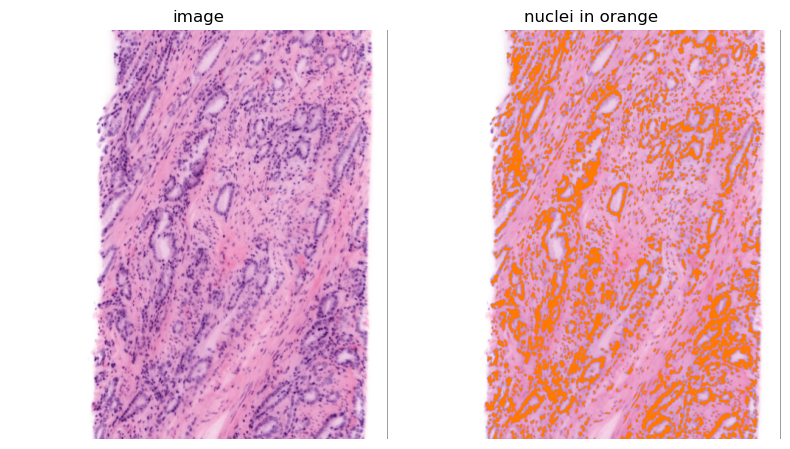

In [5]:
# ============================================================
# STEP 4: FIND THE NUCLEI
# ============================================================

def find_nuclei(gray, tissue):
    return (gray < NUCLEI_GRAY_MAX) & tissue        # dark AND inside tissue

nuclei = find_nuclei(gray, tissue)
print(f"nuclei fraction of tissue in this slice: {nuclei.sum() / tissue.sum():.1%}")

overlay = img.copy()
overlay[nuclei] = [255, 120, 0]                     # paint nuclei orange
fig, ax = plt.subplots(1, 2, figsize=(8, 8))
ax[0].imshow(img[rows]);     ax[0].set_title("image")
ax[1].imshow(overlay[rows]); ax[1].set_title("nuclei in orange")
for a in ax: a.axis("off")
plt.tight_layout()
plt.savefig(OUT_DIR / "step4_nuclei.png", dpi=120)
plt.show()

**Result.** 19.2% of tissue pixels in the example level are nuclei. Nuclei line the glands and are scattered through the stroma; dense clusters away from glands are inflammation.

## Step 5: Find the lumens (lined-by-cells test)

Not every white hole inside the tissue is a gland lumen: handling cracks, stromal clefts and pale patches look similar. A real lumen is lined by epithelial cells, so for each hole:

1. draw a ring `RING_PX` = 8 px (about 14 µm, one cell) around it;
2. measure the fraction of the ring that is nuclei;
3. accept the hole as a lumen if that fraction is at least `RING_NUCLEI_MIN` (0.20), otherwise reject it.

Thin-walled glands can score as low as tears, so the cut is a trade-off. The same rule is applied at every depth, so a consistent undercount affects all levels alike, which matters less for a study of change with depth than an error that varies with depth.

holes tested: 276, accepted as lumen: 83
lumen fraction of this slice: 2.07%  (rejected white space: 2.06%)


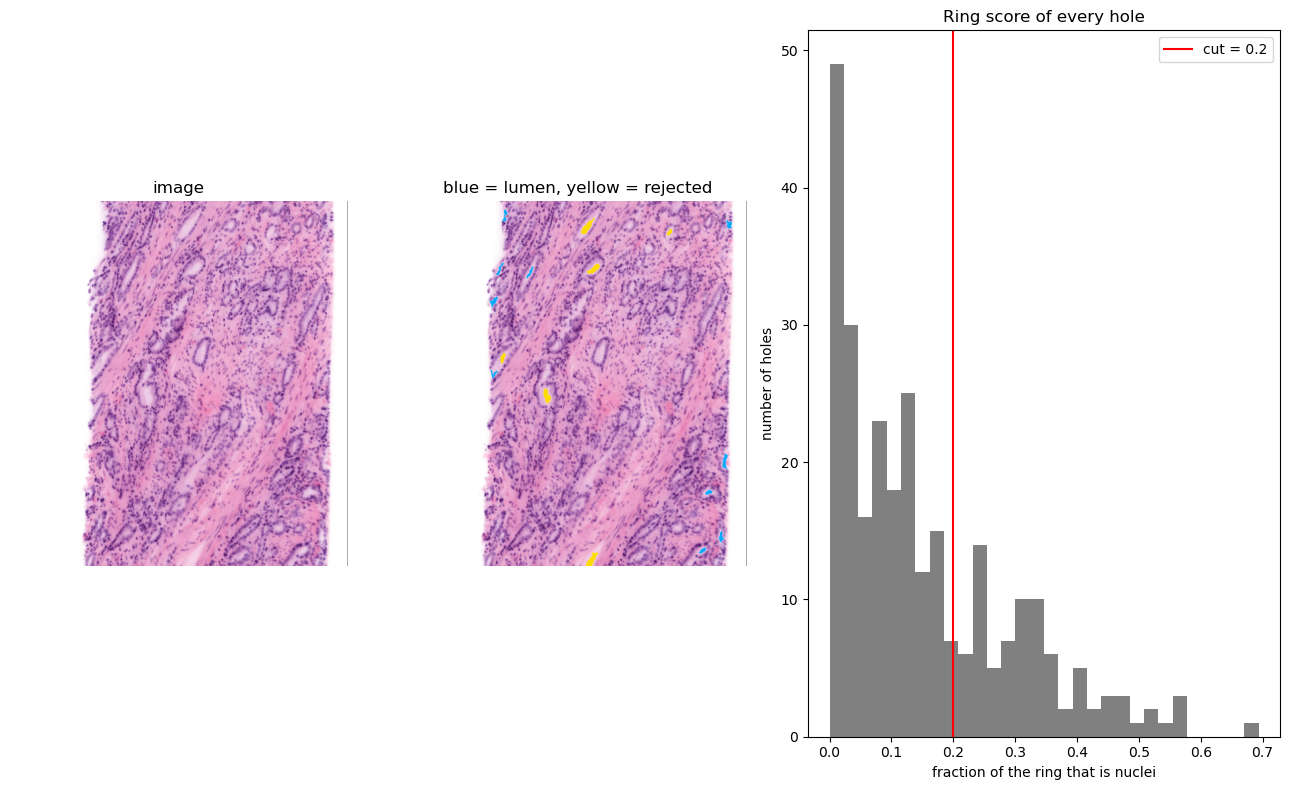

In [6]:
# ============================================================
# STEP 5: FIND THE LUMENS
# ============================================================

def find_lumens(tissue, outline, nuclei):
    candidates = outline & ~tissue                        # white holes inside the core
    labels, n = ndi.label(candidates)                     # give each hole its own number
    sizes = np.bincount(labels.ravel())                   # size of each hole in pixels
    lumen = np.zeros_like(candidates)                     # holes we accept
    rejected = np.zeros_like(candidates)                  # holes we reject (cracks, clefts)
    scores = []                                           # keep each hole's ring score so we can inspect them

    for i, box in enumerate(ndi.find_objects(labels), start=1):   # box = the rectangle around hole i
        if box is None or sizes[i] < MIN_LUMEN_PX:
            continue                                      # too small to be a lumen: ignore it
        # Work in a small rectangle around the hole (much faster than the whole image).
        r0 = max(box[0].start - RING_PX - 1, 0);  r1 = box[0].stop + RING_PX + 1
        c0 = max(box[1].start - RING_PX - 1, 0);  c1 = box[1].stop + RING_PX + 1
        hole = labels[r0:r1, c0:c1] == i
        # The ring: grow the hole outwards by RING_PX pixels, then remove the hole itself.
        ring = ndi.binary_dilation(hole, iterations=RING_PX) & ~hole & tissue[r0:r1, c0:c1]
        score = nuclei[r0:r1, c0:c1][ring].mean() if ring.any() else 0.0   # fraction of the ring that is nuclei
        scores.append(score)
        if score >= RING_NUCLEI_MIN:
            lumen[r0:r1, c0:c1] |= hole
        else:
            rejected[r0:r1, c0:c1] |= hole
    return lumen, rejected, np.array(scores)

lumen, rejected, scores = find_lumens(tissue, outline, nuclei)
print(f"holes tested: {len(scores)}, accepted as lumen: {(scores >= RING_NUCLEI_MIN).sum()}")
print(f"lumen fraction of this slice: {lumen.sum() / outline.sum():.2%}  (rejected white space: {rejected.sum() / outline.sum():.2%})")

# Picture 1: blue = accepted lumen, yellow = rejected.
overlay = img.copy()
overlay[lumen] = [0, 170, 255]
overlay[rejected] = [255, 220, 0]
fig, ax = plt.subplots(1, 3, figsize=(13, 8), gridspec_kw={"width_ratios": [1, 1, 1.4]})
ax[0].imshow(img[rows]);     ax[0].set_title("image"); ax[0].axis("off")
ax[1].imshow(overlay[rows]); ax[1].set_title("blue = lumen, yellow = rejected"); ax[1].axis("off")
# Picture 2: where the cut sits among all the ring scores.
ax[2].hist(scores, bins=30, color="grey")
ax[2].axvline(RING_NUCLEI_MIN, color="red", label=f"cut = {RING_NUCLEI_MIN}")
ax[2].set_xlabel("fraction of the ring that is nuclei"); ax[2].set_ylabel("number of holes")
ax[2].set_title("Ring score of every hole"); ax[2].legend()
plt.tight_layout()
plt.savefig(OUT_DIR / "step5_lumens.png", dpi=120)
plt.show()

**Result.** 83 of 276 holes (30%) pass the test. The rejected white space (2.06%) is about equal to the accepted lumen (2.07%), so without the test gland space would roughly double. In the ring-score histogram most holes score near 0 (unlined cracks), with a tail of lined lumens; errors concentrate near the cut.

## Step 6: Measure every window of every level

Steps 1 to 5 run on every level of every core (396 levels). Each level is divided into fixed 1 mm windows along the core, and each window records:

* **lumen fraction** = lumen pixels ÷ (tissue + lumen pixels)
* **nuclei fraction** = nuclei pixels ÷ tissue pixels

Because the levels of a core are aligned, a window index refers to the same 1 mm of tissue at every depth. Windows less than 25% tissue (core ends) are skipped. Output: `outputs/measurements.csv`, one row per window per level.

In [7]:
# ============================================================
# STEP 6: MEASURE EVERY WINDOW OF EVERY SLICE
# ============================================================

def measure_slice(row):
    # Steps 1 to 5 in one go, for one slice.
    img = load_slice(row.file)
    gray, sat = colour_channels(img)
    tissue, outline = outline_tissue(sat)
    nuclei = find_nuclei(gray, tissue)
    lumen, rejected, _ = find_lumens(tissue, outline, nuclei)

    results = []
    width = img.shape[1]
    for w, top in enumerate(range(0, img.shape[0] - WINDOW_PX + 1, WINDOW_PX)):   # fixed windows from the top of the image
        win = slice(top, top + WINDOW_PX)
        out_px = outline[win].sum()
        if out_px < MIN_TISSUE_FRAC * WINDOW_PX * width:
            continue                                        # mostly empty (end of the core): skip
        results.append({
            "core": row.core,
            "grade": row.grade,
            "depth_um": row.depth_um,
            "window": w,
            "lumen_frac":  lumen[win].sum() / max(tissue[win].sum() + lumen[win].sum(), 1),
            "nuclei_frac": nuclei[win].sum() / max(tissue[win].sum(), 1),
            "rejected_frac": rejected[win].sum() / out_px,  # kept so we can check the ring rule later
        })
    return results

rows_out = []
for i, row in enumerate(slices.itertuples()):
    rows_out += measure_slice(row)
    if i % 11 == 0:
        print(f"done {i + 1} of {len(slices)} slices")

table = pd.DataFrame(rows_out)
table.to_csv(OUT_DIR / "measurements.csv", index=False)
print(f"\nSaved {len(table)} rows to outputs/measurements.csv")

# A first summary: average over every window and depth, per core.
print(table.groupby(["core", "grade"])[["lumen_frac", "nuclei_frac"]].mean().round(3))
print("\nwindows per core:", table.groupby("core")["window"].nunique().to_dict())

done 1 of 396 slices
done 12 of 396 slices
done 23 of 396 slices
done 34 of 396 slices
done 45 of 396 slices
done 56 of 396 slices
done 67 of 396 slices
done 78 of 396 slices
done 89 of 396 slices
done 100 of 396 slices
done 111 of 396 slices
done 122 of 396 slices
done 133 of 396 slices
done 144 of 396 slices
done 155 of 396 slices
done 166 of 396 slices
done 177 of 396 slices
done 188 of 396 slices
done 199 of 396 slices
done 210 of 396 slices
done 221 of 396 slices
done 232 of 396 slices
done 243 of 396 slices
done 254 of 396 slices
done 265 of 396 slices
done 276 of 396 slices
done 287 of 396 slices
done 298 of 396 slices
done 309 of 396 slices
done 320 of 396 slices
done 331 of 396 slices
done 342 of 396 slices
done 353 of 396 slices
done 364 of 396 slices
done 375 of 396 slices
done 386 of 396 slices

Saved 4227 rows to outputs/measurements.csv
                          lumen_frac  nuclei_frac
core        grade                                
PRD_P000_A  higher grade       0.025 

**Result.** 4,227 rows: 132 windows x 33 levels = 4,356, minus 129 rows from 8 windows at ragged core ends that fall below the tissue threshold at some depths.

Gland space averages 2% to 11% by core, and nuclei 15% to 36%. Average gland space is almost identical for the higher-grade (about 6.3%) and low-grade (about 6.5%) groups. Likely reasons: the label describes one level while each core also contains benign glands and stroma, and grade depends on gland shape more than on total open space. The analysis therefore studies change with depth, not averages.

## Step 7: Visual check

For each core, the window with the most gland space is drawn at the top, middle and bottom level (about 0, 80 and 160 µm deep), with lumens in blue, rejected holes in yellow and nuclei in orange.

Checks: blue on real gland centres; yellow on cracks and pale stroma; orange on nuclei (not edge artefacts); edge glands handled consistently; visible change across depth.

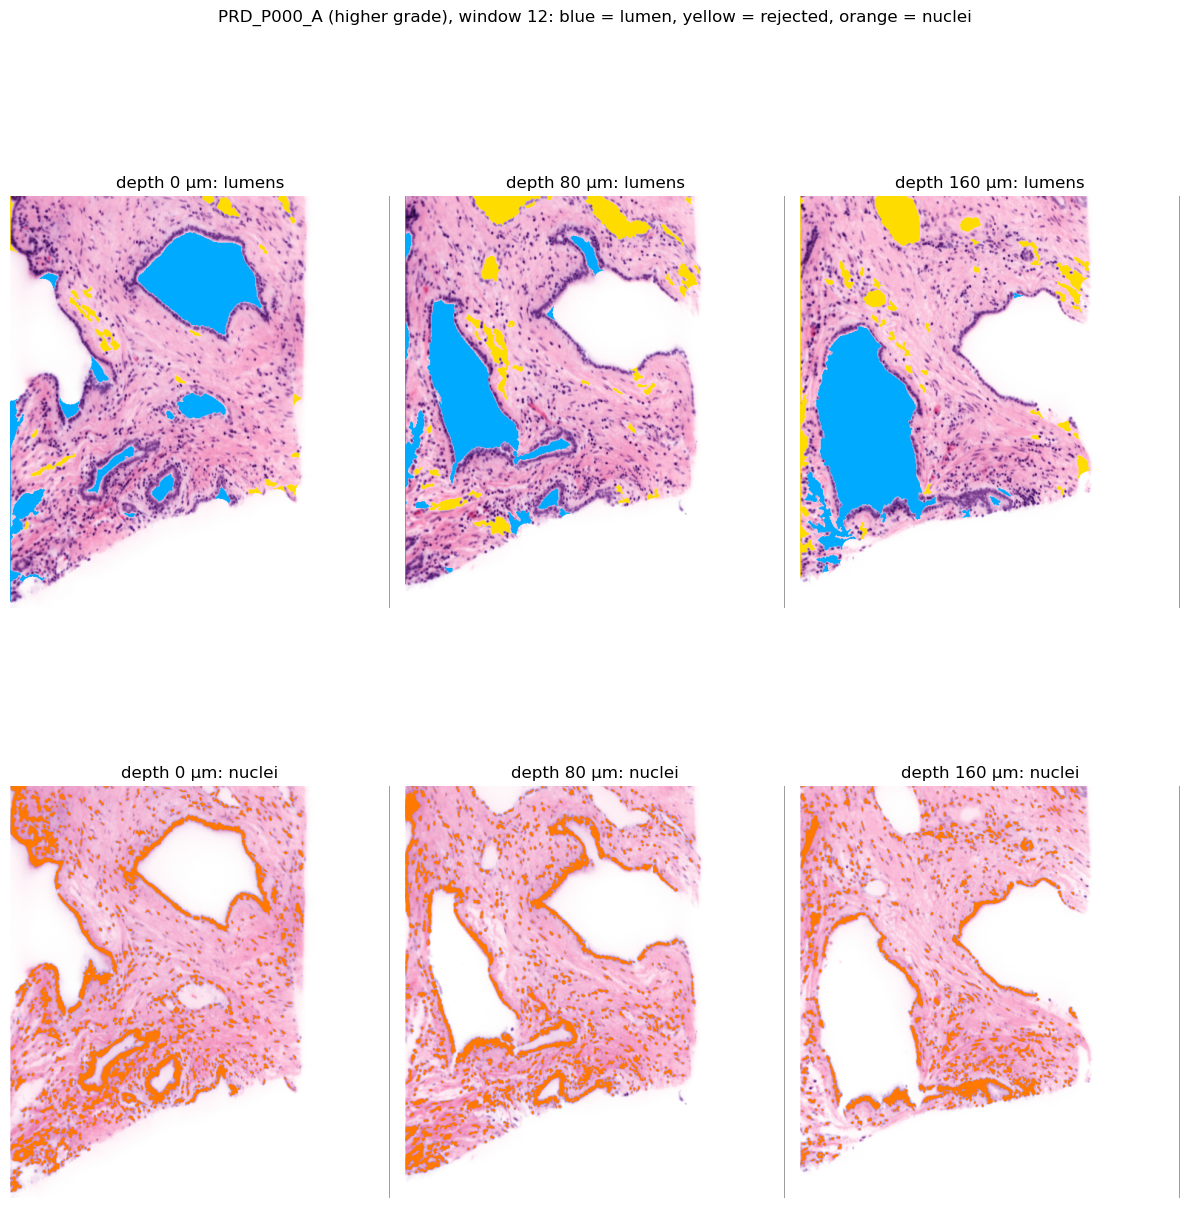

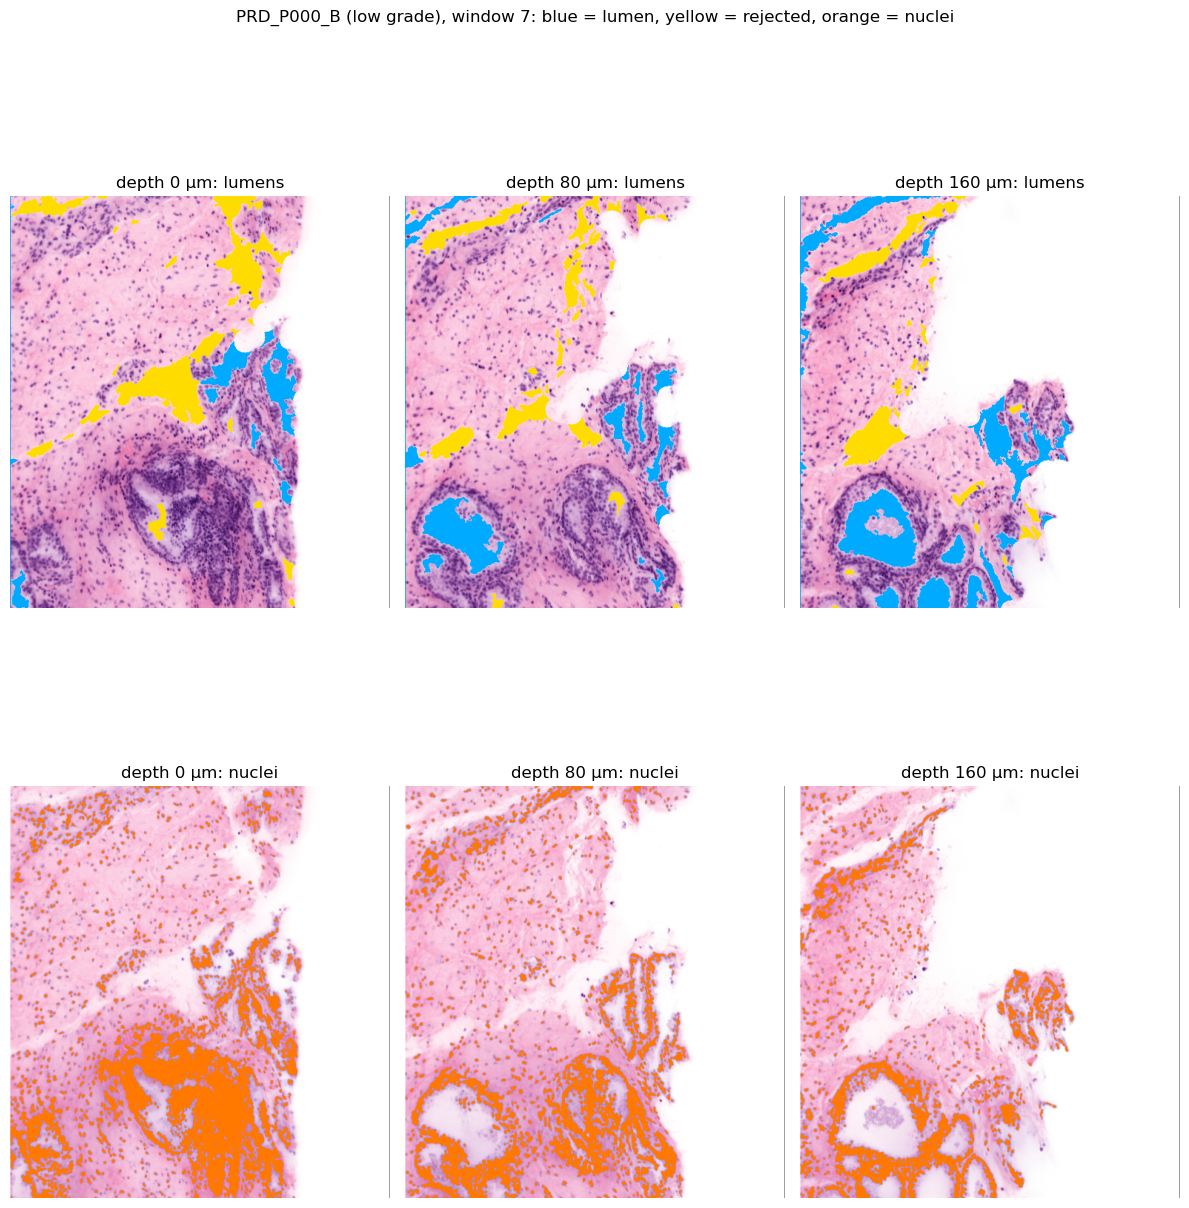

Saved the check pictures in outputs/.


[Check pictures for the other 10 cores are omitted here to keep the file small; rerunning the notebook regenerates all 12.]


In [8]:
# ============================================================
# STEP 7: VISUAL CHECK
# ============================================================

def masks_for(path):
    # Steps 1 to 5 again, but returning the masks so we can draw them.
    img = load_slice(path)
    gray, sat = colour_channels(img)
    tissue, outline = outline_tissue(sat)
    nuclei = find_nuclei(gray, tissue)
    lumen, rejected, _ = find_lumens(tissue, outline, nuclei)
    return img, nuclei, lumen, rejected

for core in CORES:
    # The window with the most lumen in this core, averaged over depth.
    best = table[table.core == core].groupby("window")["lumen_frac"].mean().idxmax()
    win = slice(best * WINDOW_PX, (best + 1) * WINDOW_PX)
    stack = slices[slices.core == core].reset_index(drop=True)
    picks = [0, len(stack) // 2, len(stack) - 1]            # top, middle, bottom slice

    fig, ax = plt.subplots(2, 3, figsize=(12, 14))
    for j, k in enumerate(picks):
        img, nuclei, lumen, rejected = masks_for(stack.file[k])
        a = img[win].copy()
        a[lumen[win]] = [0, 170, 255]                       # blue: lumen
        a[rejected[win]] = [255, 220, 0]                    # yellow: rejected hole
        b = img[win].copy()
        b[nuclei[win]] = [255, 120, 0]                      # orange: nuclei
        ax[0, j].imshow(a); ax[0, j].set_title(f"depth {stack.depth_um[k]:.0f} µm: lumens"); ax[0, j].axis("off")
        ax[1, j].imshow(b); ax[1, j].set_title(f"depth {stack.depth_um[k]:.0f} µm: nuclei"); ax[1, j].axis("off")
    fig.suptitle(f"{core} ({CORES[core]}), window {best}: blue = lumen, yellow = rejected, orange = nuclei", fontsize=12)
    plt.tight_layout()
    plt.savefig(OUT_DIR / f"step7_check_{core}.png", dpi=120)
    plt.show()

print("Saved the check pictures in outputs/.")

**Result.** Glands are branching tubes that run at angles through the core, so the same 1 mm of tissue looks different at different depths: glands appear, change shape and disappear over 160 µm. Some windows show abrupt steps in gland space that look like the segmentation changing its decision on a single large lumen (at the core edge or near the ring-test cut). These add apparent change between levels, which makes levels look less alike; the main result is reported as an upper limit for that reason.

## Output

`outputs/measurements.csv` feeds notebook 2 (`2_ANALYSE_run_second.ipynb`).